In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("../Dataset/Salary_Data.csv")

df.head()


,YearsExperience,Age,Salary
0,1.1,21.0,39343
1,1.3,21.5,46205
2,1.5,21.7,37731
3,2.0,22.0,43525
4,2.2,22.2,39891


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (30, 3)

Column Names:
['YearsExperience', 'Age', 'Salary']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Age              30 non-null     float64
 2   Salary           30 non-null     int64  
dtypes: float64(2), int64(1)
memory usage: 852.0 bytes


In [5]:
df.describe()

,YearsExperience,Age,Salary
count,30.000000,30.000000,30.000000
mean,5.313333,27.216667,76003.000000
std,2.837888,5.161267,27414.429785
min,1.100000,21.000000,37731.000000
25%,3.200000,23.300000,56720.750000
50%,4.700000,25.000000,65237.000000
75%,7.700000,30.750000,100544.750000
max,10.500000,38.000000,122391.000000


In [6]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Missing Values:
YearsExperience    0
Age                0
Salary             0
dtype: int64

Duplicate Rows:
0


In [7]:
df = df.drop_duplicates()

print("Data Cleaning Completed!")
print("Final Dataset Shape:", df.shape)

Data Cleaning Completed!
Final Dataset Shape: (30, 3)


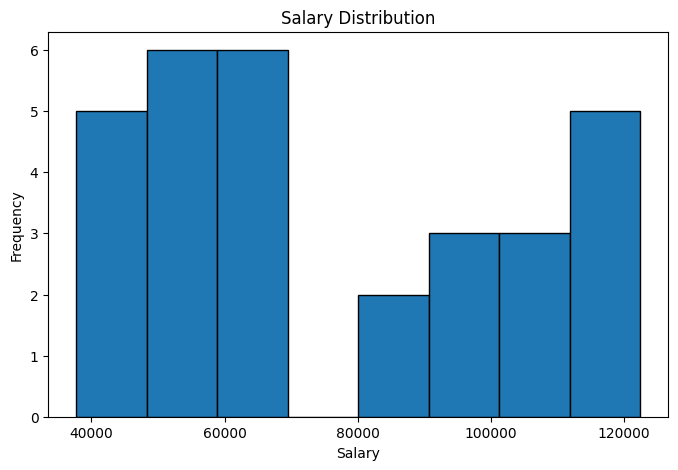

In [8]:
plt.figure(figsize=(8, 5))

plt.hist(df['Salary'], bins=8, edgecolor='black')

plt.title('Salary Distribution')
plt.xlabel('Salary')
plt.ylabel('Frequency')

plt.show()

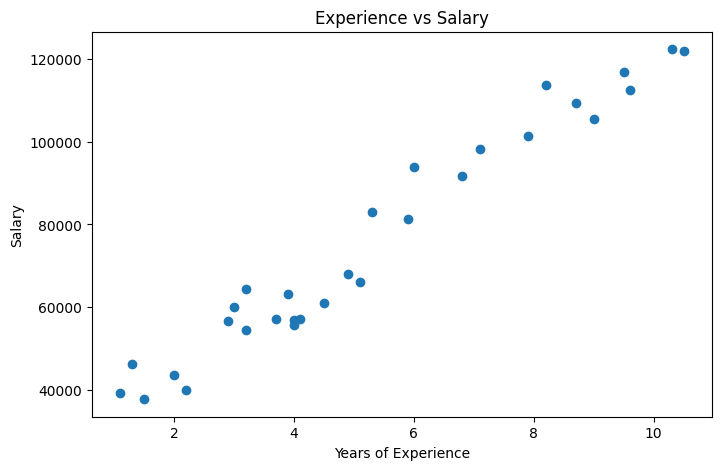

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(df['YearsExperience'], df['Salary'])

plt.title('Experience vs Salary')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')

plt.show()

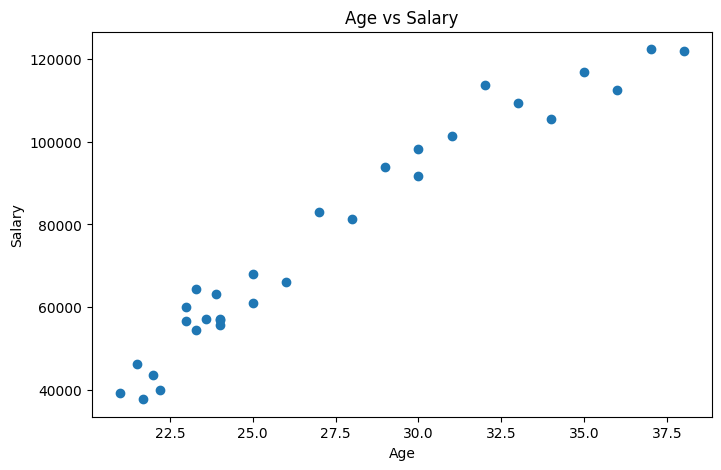

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Age'], df['Salary'])

plt.title('Age vs Salary')
plt.xlabel('Age')
plt.ylabel('Salary')

plt.show()

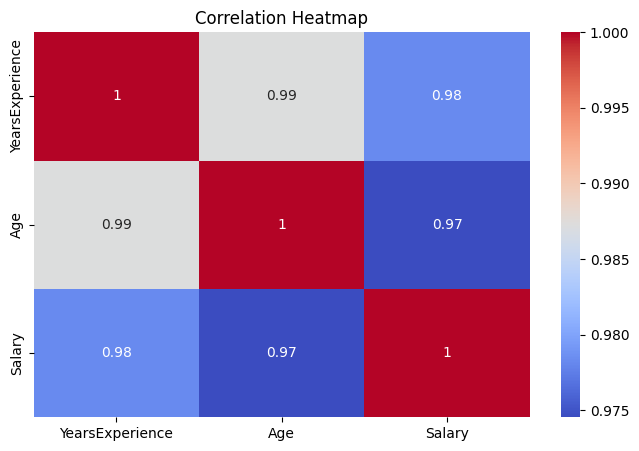

In [11]:
plt.figure(figsize=(8, 5))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap')

plt.show()

In [12]:
X = df[['YearsExperience', 'Age']]
y = df['Salary']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   YearsExperience   Age
0              1.1  21.0
1              1.3  21.5
2              1.5  21.7
3              2.0  22.0
4              2.2  22.2

Target:
0    39343
1    46205
2    37731
3    43525
4    39891
Name: Salary, dtype: int64


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (24, 2)
Testing Data: (6, 2)


In [14]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [15]:
y_pred = model.predict(X_test)

print("Actual Salaries:")
print(y_test.values)

print("\nPredicted Salaries:")
print(y_pred)

Actual Salaries:
[112635  67938 113812  83088  64445  57189]

Predicted Salaries:
[118686.60525402  67497.80208802 101581.52273219  74585.69879684
  54833.367916    58044.6977654 ]


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 6281.985247730362
Root Mean Squared Error: 7657.295979259413
R2 Score: 0.8852101657216537


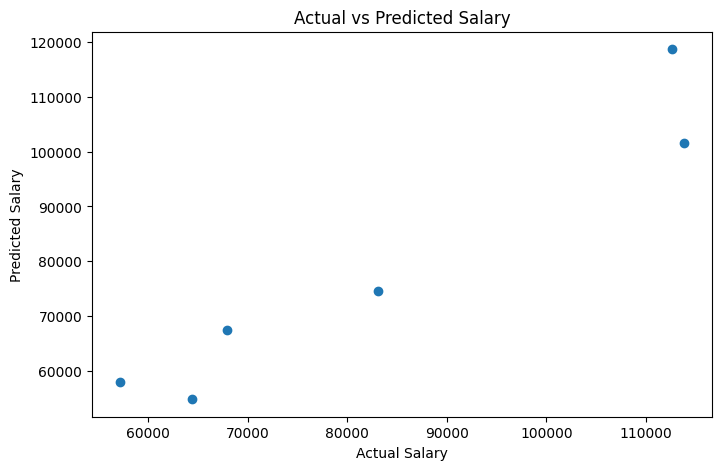

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")

plt.show()

In [18]:
new_data = pd.DataFrame({
    'YearsExperience': [5],
    'Age': [28]
})

predicted_salary = model.predict(new_data)

print("Years of Experience: 5")
print("Age: 28")
print("Predicted Salary:", round(predicted_salary[0], 2))

Years of Experience: 5
Age: 28
Predicted Salary: 75688.57


In [19]:
df['AgeExperienceRatio'] = df['Age'] / df['YearsExperience']

df['ExperienceLevel'] = pd.cut(
    df['YearsExperience'],
    bins=[0, 3, 7, 11],
    labels=['Entry', 'Mid', 'Senior']
)

df.head()

,YearsExperience,Age,Salary,AgeExperienceRatio,ExperienceLevel
0,1.1,21.0,39343,19.090909,Entry
1,1.3,21.5,46205,16.538462,Entry
2,1.5,21.7,37731,14.466667,Entry
3,2.0,22.0,43525,11.000000,Entry
4,2.2,22.2,39891,10.090909,Entry


In [20]:
X_new = df[['YearsExperience', 'Age', 'AgeExperienceRatio', 'ExperienceLevel']]

X_new = pd.get_dummies(X_new, columns=['ExperienceLevel'], drop_first=True)

y_new = df['Salary']

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new, y_new, test_size=0.2, random_state=42
)

improved_model = LinearRegression()

improved_model.fit(X_train_new, y_train_new)

y_pred_new = improved_model.predict(X_test_new)

print("Improved Model Training Completed!")

Improved Model Training Completed!


In [21]:
mae_new = mean_absolute_error(y_test_new, y_pred_new)
rmse_new = np.sqrt(mean_squared_error(y_test_new, y_pred_new))
r2_new = r2_score(y_test_new, y_pred_new)

print("Improved Model Results")
print("MAE:", mae_new)
print("RMSE:", rmse_new)
print("R2 Score:", r2_new)

print("\nBaseline Model R2:", r2)
print("Improved Model R2:", r2_new)

Improved Model Results
MAE: 6353.644582016622
RMSE: 7792.663028130484
R2 Score: 0.8811157413584967

Baseline Model R2: 0.8852101657216537
Improved Model R2: 0.8811157413584967
